# Reducción de dimensionalidad (PCA y SVD) y clustering jerárquico
**Universidad de Cundinamarca – Esp. Inteligencia Artificial – Introducción a Machine Learning (2026-2)**  
**Estudiante:** Laura Fernanda López Mayorga  

Versión adaptada del ejemplo `Algoritmo_InmueblesPCA.py` para leer `DATASET_INmuebles.xlsx`, estudiar la varianza explicada, visualizar los grupos de K-Means en el plano PC1-PC2, comparar con SVD y con clustering jerárquico.

## 1. Librerías, carga y preprocesamiento

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

RUTA = "DATASET_INmuebles.xlsx"
# En Google Colab: si el archivo no está en el entorno, se solicita subirlo.
if not os.path.exists(RUTA):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Coloque DATASET_INmuebles.xlsx junto al notebook.")

In [2]:
df_raw = pd.read_excel(RUTA)
print("Dimensiones originales:", df_raw.shape)
print("Columnas originales:", list(df_raw.columns))
df_raw.head()

Dimensiones originales: (1000, 10)
Columnas originales: ['Inmueble', 'Área m²', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


In [3]:
# Normalización de nombres de columnas (el archivo trae 'Antig[uedad' y un segundo 'Estrato')
df = df_raw.rename(columns={
    "Inmueble": "Id_inmueble", "Área m²": "Area_m2", "Precio arriendo": "Precio_arriendo",
    "Baños": "Banos", "Antig[uedad": "Antiguedad_anios", "Tipo Inmueble": "Tipo_inmueble",
    "Estrato.1": "Estrato_dup"})

print("Valores nulos:", int(df.isna().sum().sum()))
print("Registros duplicados (sin Id):", int(df.drop(columns="Id_inmueble").duplicated().sum()))
print("Correlación Estrato vs Estrato_dup:", round(df["Estrato"].corr(df["Estrato_dup"]), 3))
print("Coincidencia exacta entre ambos estratos:", f'{(df["Estrato"] == df["Estrato_dup"]).mean():.1%}')
print("\nRelación Localidad vs Tipo_inmueble:")
print(pd.crosstab(df["Localidad"], df["Tipo_inmueble"]))

Valores nulos: 0
Registros duplicados (sin Id): 0
Correlación Estrato vs Estrato_dup: 0.041
Coincidencia exacta entre ambos estratos: 16.7%

Relación Localidad vs Tipo_inmueble:
Tipo_inmueble  ApartaEstudio  Apto  Casa
Localidad                               
Chapinero                  0     0   333
Suba                       0   334     0
Usaquén                  333     0     0


**Decisiones de preprocesamiento**

* `Id_inmueble` se conserva para identificar registros, pero **no** se usa en el cálculo de distancias (requisito del enunciado).
* El archivo trae dos columnas de estrato. `Estrato` (rango 2–6) está fuertemente correlacionada con precio y área, mientras `Estrato_dup` (rango 1–4) coincide solo en ~17 % de los casos y su correlación con `Estrato` es ≈ 0.04, por lo que se trata como una columna inconsistente y se excluye.
* `Localidad` y `Tipo_inmueble` son redundantes: cada localidad tiene un único tipo (Chapinero → Casa, Suba → Apto, Usaquén → ApartaEstudio). Codificar ambas duplicaría el peso de la ubicación, por eso solo se codifica `Localidad` con One-Hot.
* Las variables numéricas se estandarizan (media 0, desviación 1) porque K-Means y PCA son sensibles a la escala; sin esto el precio (millones de pesos) dominaría todas las distancias.

In [4]:
NUM = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
CAT = ["Localidad"]

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(sparse_output=False), CAT)])
X = preprocesador.fit_transform(df)
nombres = [n.replace("num__", "").replace("cat__", "") for n in preprocesador.get_feature_names_out()]
print("Matriz para el modelo:", X.shape)
print(nombres)

def ordenar_por_precio(etiquetas):
    """Renumera los clústeres de menor a mayor precio medio para que la lectura sea estable."""
    orden = df.groupby(etiquetas)["Precio_arriendo"].mean().sort_values().index
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[e] for e in etiquetas])

def perfil(etiquetas):
    g = df.assign(Cluster=etiquetas).groupby("Cluster")
    p = g[NUM].mean().round(2)
    p["Precio_arriendo"] = p["Precio_arriendo"].round(0)
    p["N_inmuebles"] = g.size()
    return p

Matriz para el modelo: (1000, 9)
['Precio_arriendo', 'Area_m2', 'Habitaciones', 'Banos', 'Antiguedad_anios', 'Estrato', 'Localidad_Chapinero', 'Localidad_Suba', 'Localidad_Usaquén']


In [5]:
print("Dimensiones antes del preprocesamiento:", df_raw.shape, "-> 9 columnas sin el Id")
print("Variables usadas antes de codificar: 6 numéricas + 1 categórica = 7")
print("Dimensiones después del preprocesamiento:", X.shape)

Dimensiones antes del preprocesamiento: (1000, 10) -> 9 columnas sin el Id
Variables usadas antes de codificar: 6 numéricas + 1 categórica = 7
Dimensiones después del preprocesamiento: (1000, 9)


## 2. PCA: varianza explicada

,Componente,Varianza_%,Acumulada_%
0,PC1,51.15,51.15
1,PC2,15.11,66.26
2,PC3,14.90,81.16
3,PC4,5.04,86.20
4,PC5,4.99,91.19
5,PC6,3.67,94.85
6,PC7,2.99,97.84
7,PC8,2.16,100.00
8,PC9,0.00,100.00


Componentes necesarios para >= 80 %: 3
Componentes necesarios para >= 90 %: 5


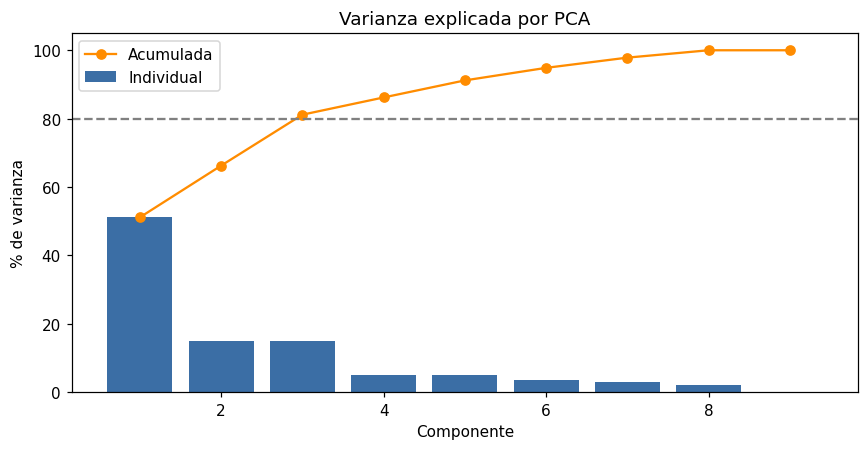

In [6]:
pca_full = PCA().fit(X)
ev = pca_full.explained_variance_ratio_
tabla_var = pd.DataFrame({"Componente": [f"PC{i+1}" for i in range(len(ev))],
                          "Varianza_%": (ev * 100).round(2),
                          "Acumulada_%": (np.cumsum(ev) * 100).round(2)})
display(tabla_var)
print("Componentes necesarios para >= 80 %:", int(np.argmax(np.cumsum(ev) >= .80) + 1))
print("Componentes necesarios para >= 90 %:", int(np.argmax(np.cumsum(ev) >= .90) + 1))

fig, a = plt.subplots(figsize=(8, 4.2))
a.bar(range(1, len(ev) + 1), ev * 100, color="#3b6ea5", label="Individual")
a.plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, "o-", color="darkorange", label="Acumulada")
a.axhline(80, ls="--", color="gray"); a.set_xlabel("Componente"); a.set_ylabel("% de varianza")
a.set_title("Varianza explicada por PCA"); a.legend(); plt.tight_layout()
plt.savefig("figuras/f4_varianza_pca.png", dpi=150); plt.show()

In [7]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print("Dimensiones después de PCA:", Z.shape)
print(f"Varianza explicada PC1 + PC2: {pca.explained_variance_ratio_.sum():.2%}")
cargas = pd.DataFrame(pca_full.components_[:3].T, index=nombres, columns=["PC1", "PC2", "PC3"]).round(3)
cargas

Dimensiones después de PCA: (1000, 2)
Varianza explicada PC1 + PC2: 66.26%


,PC1,PC2,PC3
Precio_arriendo,0.501,-0.015,-0.029
Area_m2,0.493,0.029,0.003
Habitaciones,0.493,0.008,0.017
Banos,0.016,-0.669,0.742
Antiguedad_anios,-0.022,0.741,0.669
Estrato,0.512,0.032,0.016
Localidad_Chapinero,-0.011,0.003,-0.004
Localidad_Suba,-0.014,0.011,0.011
Localidad_Usaquén,0.024,-0.014,-0.007


## 3. Grupos de K-Means vistos en el plano PC1-PC2

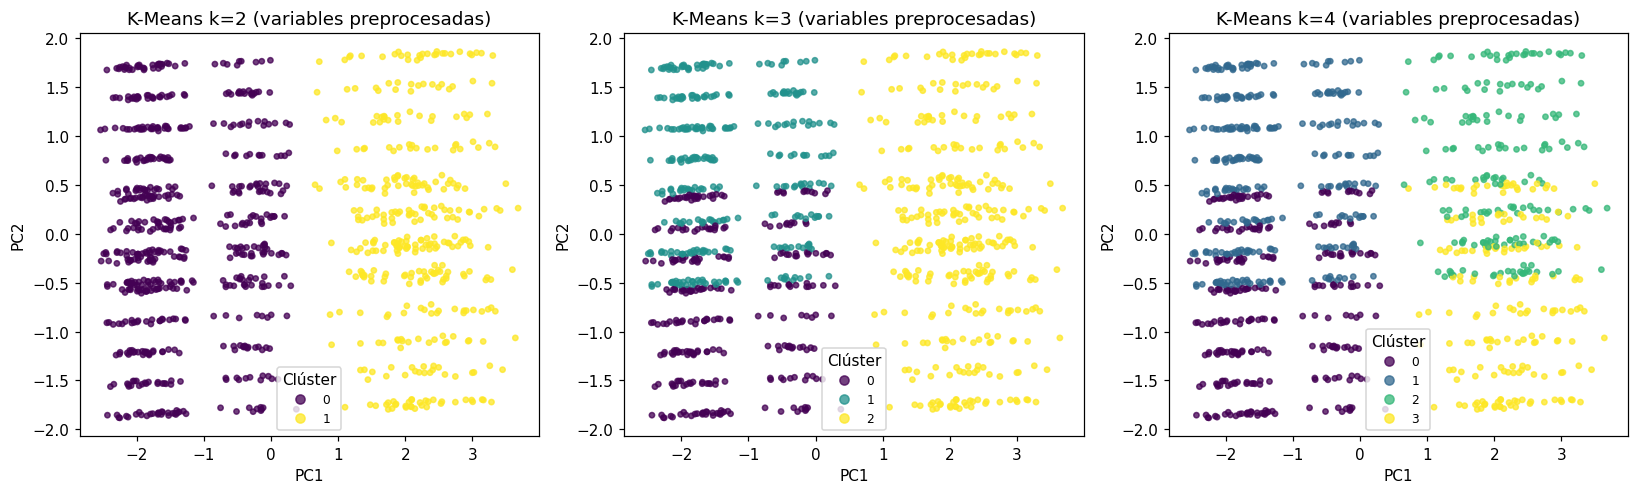

In [8]:
etiquetas = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, k in zip(ax, [2, 3, 4]):
    etiquetas[k] = ordenar_por_precio(KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X))
    sc = a.scatter(Z[:, 0], Z[:, 1], c=etiquetas[k], cmap="viridis", s=12, alpha=.75)
    a.set_title(f"K-Means k={k} (variables preprocesadas)"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
    a.legend(*sc.legend_elements(), title="Clúster", fontsize=8)
plt.tight_layout(); plt.savefig("figuras/f5_kmeans_en_pca.png", dpi=150); plt.show()

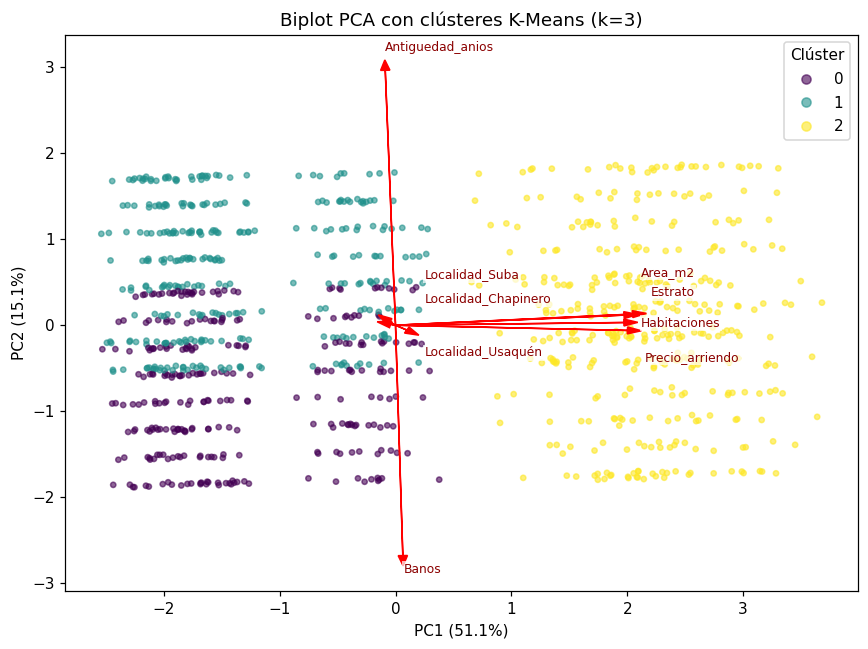

In [9]:
fig, a = plt.subplots(figsize=(8, 6))
sc = a.scatter(Z[:, 0], Z[:, 1], c=etiquetas[3], cmap="viridis", s=12, alpha=.6)
desplaz = {"Precio_arriendo": -0.35, "Area_m2": 0.45, "Habitaciones": -0.05, "Estrato": 0.2,
           "Localidad_Chapinero": 0.25, "Localidad_Suba": 0.5, "Localidad_Usaquén": -0.3}
for n, (x, y) in zip(nombres, pca.components_.T):
    a.arrow(0, 0, x * 4, y * 4, color="red", head_width=.08)
    xt = x * 4.3 if not n.startswith("Localidad") else 0.25
    a.text(xt, y * 4.3 + desplaz.get(n, 0), n, color="darkred", fontsize=8,
           bbox=dict(facecolor="white", alpha=.7, edgecolor="none", pad=1))
a.set_xlabel(f"PC1 ({ev[0]:.1%})"); a.set_ylabel(f"PC2 ({ev[1]:.1%})")
a.set_title("Biplot PCA con clústeres K-Means (k=3)"); a.legend(*sc.legend_elements(), title="Clúster")
plt.tight_layout(); plt.savefig("figuras/f6_biplot.png", dpi=150); plt.show()

## 4. ¿Cambian los grupos si K-Means se aplica sobre los componentes principales?

In [10]:
base = etiquetas[3]
filas = []
for nombre, datos in [("Variables preprocesadas (9D)", X),
                      ("PCA 2 componentes", Z),
                      ("PCA 1 componente (PC1)", Z[:, :1]),
                      ("PCA 5 componentes (>=90 %)", PCA(n_components=5).fit_transform(X))]:
    lab = ordenar_por_precio(KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(datos))
    filas.append({"Espacio": nombre,
                  "ARI vs base": round(adjusted_rand_score(base, lab), 3),
                  "Silueta (espacio propio)": round(silhouette_score(datos, lab), 3),
                  "Silueta (en 9D)": round(silhouette_score(X, lab), 3)})
    if nombre == "PCA 2 componentes": lab_pca2 = lab
    if nombre == "PCA 1 componente (PC1)": lab_pc1 = lab
display(pd.DataFrame(filas))
print("\nPerfil K-Means sobre PC1-PC2:"); display(perfil(lab_pca2))
print("Perfil K-Means sobre PC1:"); display(perfil(lab_pc1))

,Espacio,ARI vs base,Silueta (espacio propio),Silueta (en 9D)
0,Variables preprocesadas (9D),1.000,0.289,0.289
1,PCA 2 componentes,0.677,0.449,0.239
2,PCA 1 componente (PC1),0.556,0.743,0.184
3,PCA 5 componentes (>=90 %),1.000,0.337,0.289



Perfil K-Means sobre PC1-PC2:


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1957875.0,60.54,1.79,1.72,6.98,2.95,310
1,2021109.0,61.52,1.87,1.22,10.09,3.03,309
2,6303997.0,154.72,4.01,1.49,8.34,5.53,381


Perfil K-Means sobre PC1:


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1469202.0,49.66,1.53,1.47,8.51,2.50,419
1,3126741.0,85.45,2.51,1.47,8.59,4.04,208
2,6346727.0,155.89,4.03,1.50,8.33,5.54,373


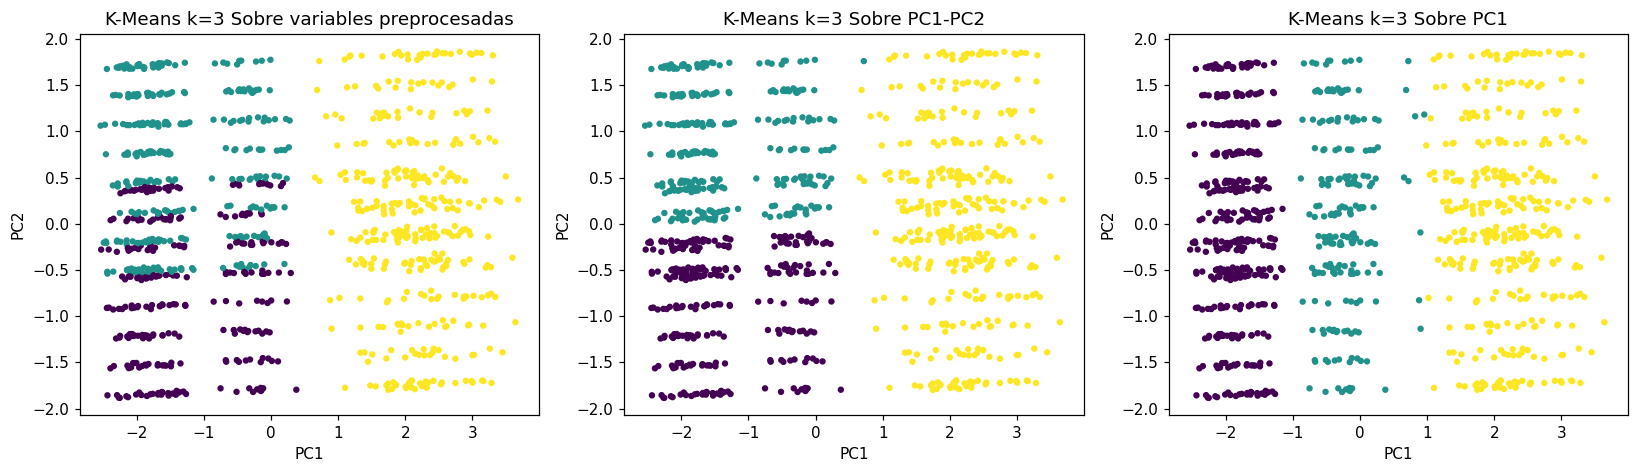

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
for a, lab, t in zip(ax, [base, lab_pca2, lab_pc1],
                     ["Sobre variables preprocesadas", "Sobre PC1-PC2", "Sobre PC1"]):
    a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="viridis", s=10); a.set_title(f"K-Means k=3 {t}")
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.savefig("figuras/f8_comparacion_espacios.png", dpi=150); plt.show()

## 5. SVD (Singular Value Decomposition)
PCA es equivalente a la SVD de la matriz centrada: X_c = U Σ Vᵀ. Las filas de Vᵀ son las direcciones principales y σᵢ² / Σσⱼ² es la varianza explicada.

Valores singulares: [58.39 31.74 31.52 18.33 18.23 15.64 14.12 11.99  0.  ]
¿Varianza SVD == varianza PCA? True
¿Direcciones iguales (salvo signo)? True
Varianza no capturada por la aproximación de rango 2: 33.74%
TruncatedSVD (sin centrar) varianza explicada: [0.5115 0.1511 0.149 ]


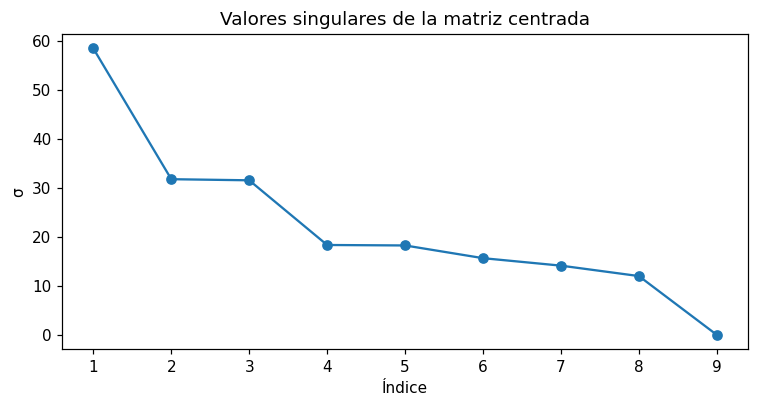

In [12]:
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
var_svd = S**2 / np.sum(S**2)
print("Valores singulares:", S.round(2))
print("¿Varianza SVD == varianza PCA?", np.allclose(var_svd, ev))
print("¿Direcciones iguales (salvo signo)?", np.allclose(np.abs(Vt[:2]), np.abs(pca.components_)))

# Reconstrucción de rango 2 y error relativo
X2 = U[:, :2] @ np.diag(S[:2]) @ Vt[:2]
print(f"Varianza no capturada por la aproximación de rango 2: {np.linalg.norm(Xc - X2)**2 / np.linalg.norm(Xc)**2:.2%}")

tsvd = TruncatedSVD(n_components=3, random_state=42).fit(X)
print("TruncatedSVD (sin centrar) varianza explicada:", tsvd.explained_variance_ratio_.round(4))

fig, a = plt.subplots(figsize=(7, 3.8))
a.plot(range(1, len(S) + 1), S, "o-"); a.set_title("Valores singulares de la matriz centrada")
a.set_xlabel("Índice"); a.set_ylabel("σ"); plt.tight_layout()
plt.savefig("figuras/f9_valores_singulares.png", dpi=150); plt.show()

## 6. Clustering jerárquico aglomerativo (Ward)

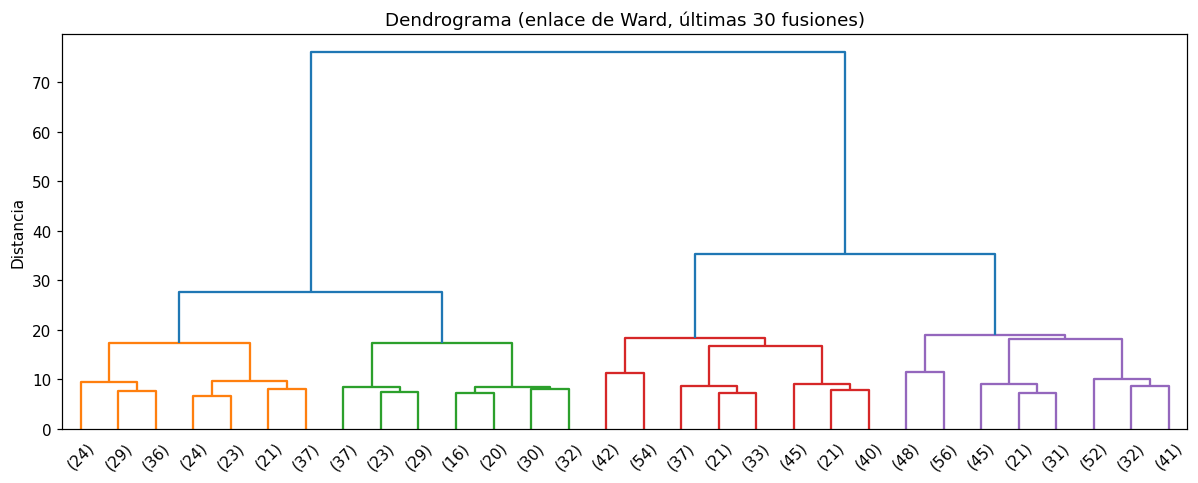

Silueta jerárquico (3 grupos): 0.289
ARI jerárquico vs K-Means k=3: 0.997


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1972691.0,60.78,1.84,2.00,8.48,2.99,293
1,2000101.0,61.25,1.83,1.00,8.56,2.99,326
2,6307757.0,154.72,4.01,1.49,8.35,5.53,381


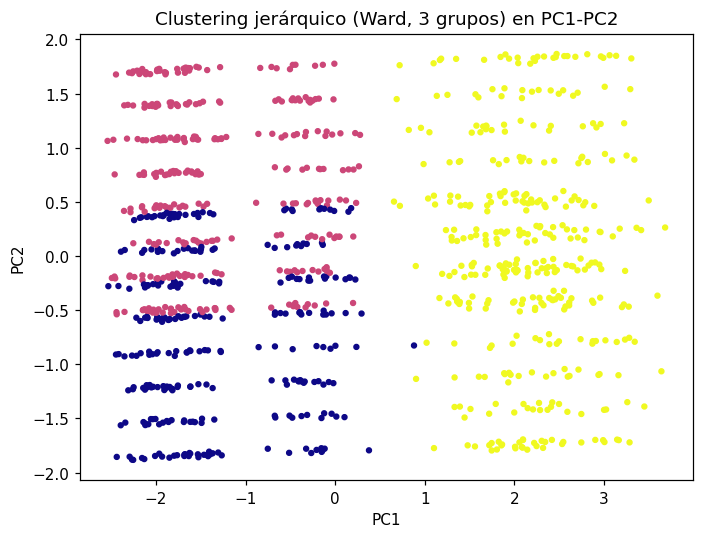

In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram
L = linkage(X, method="ward")
fig, a = plt.subplots(figsize=(11, 4.5))
dendrogram(L, truncate_mode="lastp", p=30, ax=a, color_threshold=L[-3, 2] - 1e-9)
a.set_title("Dendrograma (enlace de Ward, últimas 30 fusiones)"); a.set_ylabel("Distancia")
plt.tight_layout(); plt.savefig("figuras/f10_dendrograma.png", dpi=150); plt.show()

hc = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
lab_hc = ordenar_por_precio(hc.labels_)
print("Silueta jerárquico (3 grupos):", round(silhouette_score(X, lab_hc), 3))
print("ARI jerárquico vs K-Means k=3:", round(adjusted_rand_score(base, lab_hc), 3))
display(perfil(lab_hc))

fig, a = plt.subplots(figsize=(6.5, 5))
a.scatter(Z[:, 0], Z[:, 1], c=lab_hc, cmap="plasma", s=10)
a.set_title("Clustering jerárquico (Ward, 3 grupos) en PC1-PC2"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.savefig("figuras/f11_jerarquico_pca.png", dpi=150); plt.show()